Imports

In [1]:
import itertools
import matplotlib.pyplot as plt
import numpy as np

plt.style.use(['ggplot'])

Model Function

In [2]:
def model(w, x):

    ypred = np.dot(w, x)

    return ypred

Cost Functions

In [3]:
cost = lambda w: 0.5 * np.mean(
    (w[0] + w[1] * x - y) ** 2
)

def cost2(w, x, y):

    return 0.5 * (
        (w[0] + w[1] * x - y) ** 2
    )

Contour Plot Function

In [4]:
def plot_contour(
    f,
    x1bound,
    x2bound,
    resolution,
    ax
):

    x1range = np.linspace(
        x1bound[0],
        x1bound[1],
        resolution
    )

    x2range = np.linspace(
        x2bound[0],
        x2bound[1],
        resolution
    )

    xg, yg = np.meshgrid(
        x1range,
        x2range
    )

    zg = np.zeros_like(xg)

    w = np.array([2, 0])

    for i, j in itertools.product(
        range(resolution),
        range(resolution)
    ):

        zg[i, j] = f(
            [xg[i, j], yg[i, j]]
        )

    ax.contour(
        xg,
        yg,
        zg,
        100
    )

    return ax


Dataset

In [5]:
ndim = 2

npoints = 3

w = np.array([0, 0])

wt = np.transpose(w)

myones = np.ones(npoints)

x = np.arange(0, npoints)

x = np.vstack((myones, x))

y = model(w, x)

y = y + 2

xy = (x, y)

print(xy)

max_iterations = 50

learning_rates = np.array([
    0.01,
    0.03,
    0.05
])

(array([[1., 1., 1.],
       [0., 1., 2.]]), array([2., 2., 2.]))


Gradient Descent Helpers

In [6]:
def grad_mse(w, xy):

    (x, y) = xy

    ypredicted = model(w, x)

    diff = y - ypredicted

    grad = -np.dot(x, diff)

    return grad

In [7]:
def mse(w, xy):

    (x, y) = xy

    ypredicted = np.dot(w, x)

    loss = np.sum(
        (y - ypredicted) *
        (y - ypredicted)
    )

    m = 2 * len(y)

    loss = loss / m

    return loss

In [8]:
def gradient_descent(
    xy,
    max_iterations,
    w,
    obj_func,
    mse_func,
    grad_func,
    extra_param=[],
    learning_rate=0.05,
    momentum=0.8
):

    (x, y) = xy

    w_history = w
    f_history = obj_func(w, x)
    cost_history = mse_func(w, xy)

    delta_w = np.zeros(2)

    i = 0

    while i < max_iterations:

        delta_w = -learning_rate * grad_func(w, xy)

        w = w + delta_w

        w_history = np.vstack((w_history, w))

        ypredicted = obj_func(w, x)

        f_history = np.vstack(
            (f_history, ypredicted)
        )

        cost_history = np.vstack(
            (cost_history, mse_func(w, xy))
        )

        i += 1

    return (
        w_history,
        f_history,
        cost_history
    )

Learning Rate Comparison

[0.1164 0.1152]
[0.3276 0.3168]
[0.51 0.48]


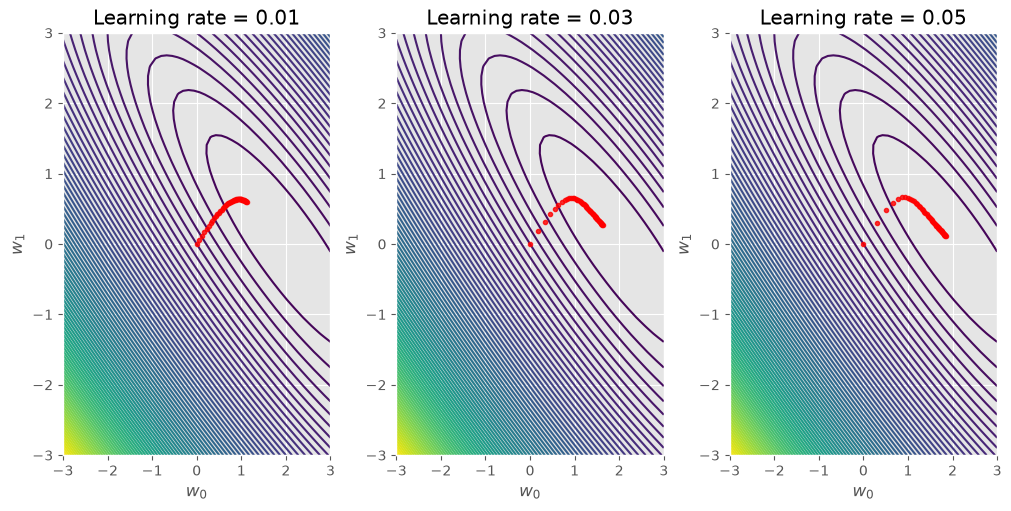

In [9]:
fig, axes = plt.subplots(
    ncols=len(learning_rates),
    nrows=1,
    constrained_layout=True,
    figsize=(10, 5)
)

for i, lr in enumerate(
    learning_rates
):

    w_hist, f_hist, c_hist = gradient_descent(
        xy,
        max_iterations,
        w,
        model,
        mse,
        grad_mse,
        learning_rate=lr,
        momentum=0.8
    )

    print(w_hist[2])

    d = 3

    plot_contour(
        cost,
        [-d, d],
        [-d, d],
        50,
        axes[i]
    )

    axes[i].plot(
        w_hist[:, 0],
        w_hist[:, 1],
        '.r',
        alpha=.8
    )

    axes[i].set_xlabel(r'$w_0$')

    axes[i].set_ylabel(r'$w_1$')

    axes[i].set_title(
        f'Learning rate = {lr}'
    )

    axes[i].set_xlim([-d, d])

    axes[i].set_ylim([-d, d])

plt.show()